<a href="https://colab.research.google.com/github/FaouziaGh/NPL-Collab/blob/main/Restaurant_Review_Prediction_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Restaurant Review Prediction / Classification
### Sentiment analysis of restaurant reviews: TF-IDF + Logistic Regression vs. BERT
---

## 1. Introduction

### 1.1 Context
Online platforms such as Yelp have turned restaurant reviews into a major source of information. Customers rely on them to choose where to eat, and owners use them to monitor their reputation. A review is rarely about one thing: it mixes opinions on food quality, service, prices and atmosphere, and the overall tone is often nuanced (for example, "great food, but the service was painfully slow").

Reading thousands of such reviews by hand is slow, costly and subjective. Natural Language Processing (NLP) makes it possible to turn this unstructured text into usable indicators automatically. Sentiment classification is one of the most widely used of these tasks.

### 1.2 Problem Statement
The goal of this project is to build and evaluate a system that automatically predicts the sentiment of a restaurant review from its text alone. Each review is assigned to one of three classes:

- **Negative**: the customer is dissatisfied.
- **Neutral**: the experience is mixed, or no clear polarity is expressed.
- **Positive**: the customer is satisfied.

The task is harder than binary sentiment analysis for two reasons. The *neutral* class is ambiguous by nature, with no sharp boundary between "mixed" and "slightly positive". Reviews also contain negations, contrasts and irony that simple word counts cannot capture.

### 1.3 Research Questions
- **RQ1.** How well does a classical baseline (TF-IDF + Logistic Regression) perform on this task?
- **RQ2.** Does a fine-tuned Transformer (BERT) significantly outperform this baseline, and on which classes?
- **RQ3.** What types of reviews are still misclassified by both approaches, and why?

### 1.4 Objectives
1. Explore and analyze a restaurant review dataset (size, class distribution, review length, data quality).
2. Apply a justified preprocessing pipeline, adapted separately to each model family.
3. Build a baseline with TF-IDF and Logistic Regression, using a majority-class classifier as a lower bound.
4. Fine-tune a BERT-based model on the same data split.
5. Compare the models with metrics suited to a possibly imbalanced dataset (accuracy, precision, recall, macro-F1, confusion matrix).
6. Analyze the errors qualitatively and quantitatively, and discuss the limitations of the approaches.

### 1.5 Research Hypotheses
Each hypothesis is testable with the experimental results.

- **H1.** TF-IDF + Logistic Regression performs clearly better than the majority-class baseline in macro-F1, and therefore provides a reliable reference point.
- **H2.** BERT outperforms the TF-IDF baseline in macro-F1, because it captures context (negation, word order, contrast) that a bag-of-words representation ignores. The gain will be checked against run-to-run variability (several seeds or a bootstrap confidence interval) before being called significant.
- **H3.** Performance differs across classes: the *neutral* class is expected to be the hardest, and most errors are expected to occur between adjacent classes (neutral vs. positive or negative) rather than between the two extremes.









In [5]:

# ==========================================
# 2. DATASET ACQUISITION
# ==========================================

import os
import requests
import zipfile

# Dataset download URL
url = "https://zenodo.org/records/18723813/files/yelp_sentiment_master_dataset.zip?download=1"

# Download the dataset
response = requests.get(url)
response.raise_for_status()

# Save ZIP file
zip_path = "/content/yelp_dataset.zip"

with open(zip_path, "wb") as file:
    file.write(response.content)

print("Dataset downloaded successfully!")

# Extract ZIP file
extract_path = "/content/yelp_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

# Display extracted files
for root, dirs, files in os.walk(extract_path):
    for filename in files:
        print(os.path.join(root, filename))


Dataset downloaded successfully!
Dataset extracted successfully!
/content/yelp_dataset/yelp_sentiment_master_dataset.csv


In [6]:

import pandas as pd
import glob

# Find CSV files
csv_files = glob.glob(
    "/content/yelp_dataset/**/*.csv",
    recursive=True
)

print("CSV files found:", csv_files)

# Load the first CSV file
if len(csv_files) > 0:
    df = pd.read_csv(csv_files[0])

    print("\nDataset loaded successfully!")
    print("Dataset shape:", df.shape)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

else:
    print("No CSV file found. Check the extracted files.")


CSV files found: ['/content/yelp_dataset/yelp_sentiment_master_dataset.csv']

Dataset loaded successfully!
Dataset shape: (14351, 11)

Column names:
['Sl No', 'stars_review', 'text', 'date', 'name', 'categories', 'city', 'state', 'stars_business', 'review_count', 'rating_review']

First 5 rows:


,Sl No,stars_review,text,date,name,categories,city,state,stars_business,review_count,rating_review
0,1,3,"If you decide to eat here, just be aware it is...",07-07-18 22:09,Turning Point of North Wales,"Restaurants, Breakfast & Brunch, Food, Juice B...",North Wales,PA,3.0,169,Neutral
1,2,3,Family diner. Had the buffet. Eclectic assortm...,05-02-14 20:30,Kettle Restaurant,"Restaurants, Breakfast & Brunch",Tucson,AZ,3.5,47,Neutral
2,3,5,"Wow! Yummy, different, delicious. Our favo...",04-01-15 0:01,Zaika,"Halal, Pakistani, Restaurants, Indian",Philadelphia,PA,4.0,181,Positive
3,4,4,Cute interior and owner (?) gave us tour of up...,14-01-17 20:54,Melt,"Sandwiches, Beer, Wine & Spirits, Bars, Food, ...",New Orleans,LA,4.0,32,Positive
4,5,1,I am a long term frequent customer of this est...,23-09-15 23:10,Dmitri's,"Mediterranean, Restaurants, Seafood, Greek",Philadelphia,PA,4.0,273,Negative


In [10]:

# ==========================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display dataset information
print("Dataset Information:")
df.info()

print("\nDataset dimensions:")
print("Number of reviews:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nStatistical description:")
display(df.describe(include="all").T)


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14351 entries, 0 to 14350
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sl No           14351 non-null  int64  
 1   stars_review    14351 non-null  int64  
 2   text            14351 non-null  object 
 3   date            14351 non-null  object 
 4   name            14351 non-null  object 
 5   categories      14351 non-null  object 
 6   city            14351 non-null  object 
 7   state           14351 non-null  object 
 8   stars_business  14351 non-null  float64
 9   review_count    14351 non-null  int64  
 10  rating_review   14351 non-null  object 
dtypes: float64(1), int64(3), object(7)
memory usage: 1.2+ MB

Dataset dimensions:
Number of reviews: 14351
Number of columns: 11

Statistical description:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Sl No,14351.0,NaN,NaN,NaN,7176.0,4142.921192,1.0,3588.5,7176.0,10763.5,14351.0
stars_review,14351.0,NaN,NaN,NaN,3.811372,1.322504,1.0,3.0,4.0,5.0,5.0
text,14351,14350,I was going to order delivery but the guy on t...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,14351,13973,12-11-14 17:51,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,14351,2526,Luke,187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categories,14351,2254,"German, Restaurants, Seafood, Cocktail Bars, F...",187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,14351,366,Philadelphia,2562,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,14351,16,PA,3818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stars_business,14351.0,NaN,NaN,NaN,3.759773,0.592612,1.0,3.5,4.0,4.0,5.0
review_count,14351.0,NaN,NaN,NaN,463.912898,672.434991,5.0,100.0,238.0,541.0,4554.0


In [11]:

# ==========================================
# MISSING VALUES AND DUPLICATES
# ==========================================

# Count missing values
print("Missing values per column:")
print(df.isnull().sum())

# Count duplicated rows
print("\nNumber of duplicated rows:")
print(df.duplicated().sum())

# Check duplicated reviews
print("\nNumber of duplicated review texts:")
print(df["text"].duplicated().sum())

# Check empty reviews
empty_reviews = df["text"].fillna("").str.strip().eq("").sum()

print("\nNumber of empty reviews:", empty_reviews)


Missing values per column:
Sl No             0
stars_review      0
text              0
date              0
name              0
categories        0
city              0
state             0
stars_business    0
review_count      0
rating_review     0
dtype: int64

Number of duplicated rows:
0

Number of duplicated review texts:
1

Number of empty reviews: 0


Sentiment distribution:
rating_review
Positive    9857
Negative    2699
Neutral     1795
Name: count, dtype: int64

Sentiment percentages:
rating_review
Positive    68.69
Negative    18.81
Neutral     12.51
Name: proportion, dtype: float64


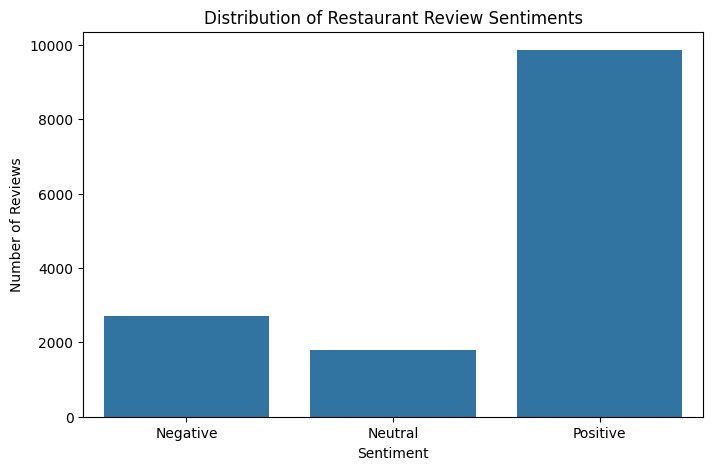

In [12]:

# ==========================================
# SENTIMENT DISTRIBUTION
# ==========================================

sentiment_counts = df["rating_review"].value_counts()

print("Sentiment distribution:")
print(sentiment_counts)

# Calculate percentages
sentiment_percentages = (
    df["rating_review"].value_counts(normalize=True) * 100
)

print("\nSentiment percentages:")
print(sentiment_percentages.round(2))

# Visualize distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="rating_review",
    order=["Negative", "Neutral", "Positive"]
)

plt.title("Distribution of Restaurant Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


Review length statistics:
count    14351.000000
mean        98.770957
std         92.014597
min          3.000000
25%         39.000000
50%         70.000000
75%        125.000000
max        926.000000
Name: review_length, dtype: float64


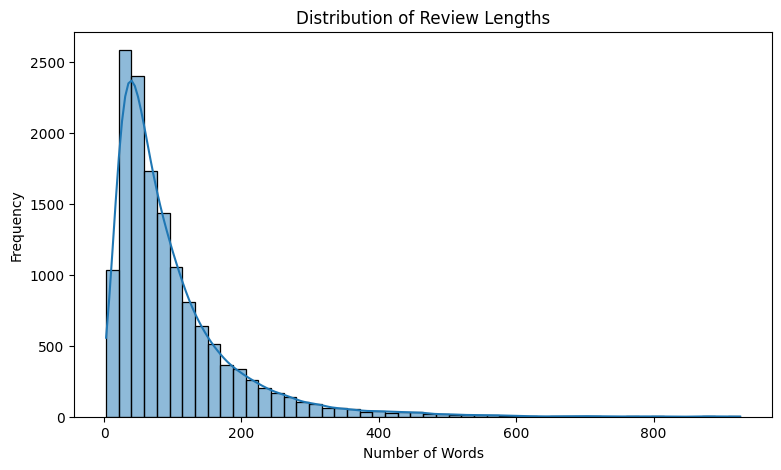


Average review length by sentiment:


,review_length
rating_review,
Negative,122.78
Neutral,115.27
Positive,89.19


In [13]:

# ==========================================
# REVIEW LENGTH ANALYSIS
# ==========================================

# Calculate the number of words in each review
df["review_length"] = df["text"].fillna("").apply(
    lambda x: len(x.split())
)

print("Review length statistics:")
print(df["review_length"].describe())

# Histogram
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="review_length",
    bins=50,
    kde=True
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

# Average length by sentiment
print("\nAverage review length by sentiment:")
display(
    df.groupby("rating_review")["review_length"]
      .mean()
      .round(2)
)


Relationship between stars and sentiment:


rating_review,Negative,Neutral,Positive
stars_review,,,
1,1422,0,0
2,1277,0,0
3,0,1795,0
4,0,0,3949
5,0,0,5908


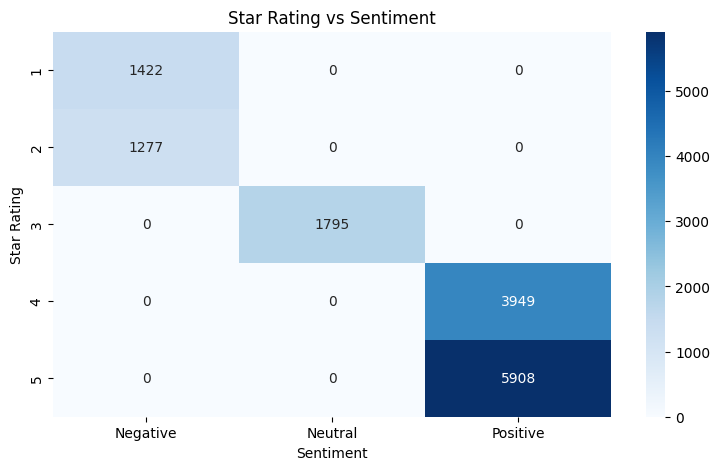

In [16]:

# ==========================================
# STAR RATING VS SENTIMENT
# ==========================================

# Cross-tabulation
rating_table = pd.crosstab(
    df["stars_review"],
    df["rating_review"]
)

print("Relationship between stars and sentiment:")
display(rating_table)

# Visualize the relationship
plt.figure(figsize=(9, 5))

sns.heatmap(
    rating_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Star Rating vs Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Star Rating")
plt.show()

## 3. Exploratory Data Analysis (EDA)

### 3.1 Dataset Overview
The dataset contains **14,351 restaurant reviews** described by **11 original features**, including the review text, the customer rating and the sentiment label. [List here the columns actually used: text → input X, sentiment → target y, stars → rating.]

### 3.2 Objectives of the EDA
Before applying any NLP technique, the EDA aims to answer five questions, each of which drives a concrete decision in the rest of the project:

| Question | Analysis | Decision it informs |
|---|---|---|
| Is the data complete and clean? | Missing values, duplicate reviews | Which rows to remove; whether the train/test split is free of leakage |
| Are the classes balanced? | Sentiment distribution | Choice of metrics (macro-F1 rather than accuracy alone), use of class weights |
| How long are the reviews? | Word and character counts, by sentiment | Truncation length (`max_length`) for BERT |
| Are the labels consistent with the ratings? | Cross-tabulation of stars and sentiment | Validation of the labeling rule; detection of label noise |
| Which words characterize each class? | Most frequent terms per sentiment | Preprocessing choices (e.g., keeping negations) and first intuition about the vocabulary |

### 3.3 Methodology
Numerical summaries and visualizations (bar plots, histograms, boxplots, a confusion-style cross-tabulation, word frequencies) are produced on the **training portion only** for any analysis that guides modeling choices. The test set is not used to make decisions.

### 3.4 Results and Interpretation
*[To be completed after running the analyses: for each question, state the figure obtained and what it implies. Example: "The neutral class represents X% of the reviews, so the dataset is imbalanced; macro-F1 will therefore be reported alongside accuracy."]*

### 3.5 Conclusions for the Experimental Strategy
*[Summarize in 3-4 bullet points the decisions taken thanks to the EDA: cleaning applied, metrics chosen, maximum sequence length, handling of class imbalance.]*